### QED-C Application-Oriented Benchmarks - Hamiltonian Paper Images - 2

This notebook creates special images that involve calculations across different backend datasets.


In [2]:
# Reference the __common files from main repo (maxcut branch for now)

# Reference the __common files from main repo (maxcut branch for now)

# Change this to location of your QED-C code repo
repo = "../QC-App-Oriented-Benchmarks-master"

import sys
sys.path.insert(1, repo)

import sys
sys.path.insert(1, repo + "/_common")
sys.path.insert(1, repo + "/_common/qiskit")

repo = repo + "/hamlib"
sys.path.insert(1, repo + "/_common")
sys.path.insert(1, repo + "/qiskit")

import metrics

# Show elapsed time in the plots below
metrics.show_elapsed_times=True

# For the set of plots collected on IBM machines below
# we need to skip large initial elapsed times
metrics.omit_initial_elapsed_time_factor = 0

# don't use log scale unless range is very large
metrics.logscale_for_times_threshold = 500



### Compare Results from Simulators with Hardware Results

### Compare Function
This needs improvement - we could copy the fidelity code from plot_metrics.
But do it later.  We'll just use the avoce images for now.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import json
from time import gmtime, strftime
from scipy.interpolate import interp1d

# Define markers for different simulators
mark_list = ['o', 's', '^', 'd', 'v', 'p', 'h']

def compare_test_results(data_list, test_list, title=None):
    """
    Compare test results from a list of files and plot the results.

    Parameters:
    - data_list: List of data file names (without path and extension)
    - test_list: List of test names to compare
    - title: Title of the plot (optional)
    """

    # Load data from JSON files
    results = {}
    for data_file in data_list:
        with open(f'__data/DATA-{data_file}.json', 'r') as f:
            results[data_file] = json.load(f)

    
    fidelity = {}
    execution_time = {}
    elapsed_time = {}
    
    # Extract relevant data from results
    for data_file, res in results.items():
        fidelity[data_file] = {}
        execution_time[data_file] = {}
        elapsed_time[data_file] = {}

        for test in test_list:
            test_key = f"Benchmark Results - {test} - Qiskit"
            try:
                # Extract the data from the JSON file
                nqubits = results[data_file][test_key]['group_metrics']['groups']
                exec_t = results[data_file][test_key]['group_metrics']['avg_exec_times']
                # Create a dictionary with qubit as key and execution time as value
                execution_time[data_file][test_key] = {int(n): exec_t for n, exec_t in zip(nqubits, exec_t)}
                elapsed_t = results[data_file][test_key]['group_metrics']['avg_elapsed_times']
                # Create a dictionary with qubit as key and elapsed time as value
                elapsed_time[data_file][test_key] = {int(n): elapsed_t for n, elapsed_t in zip(nqubits, elapsed_t)}

            except KeyError:
                print(f"{test_key} wasn't run in data file {data_file}.") 

    ###***********
    ex1 = (execution_time["BlueQubit-CPU-240707-TFIM-3"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    ex2 = (execution_time["BlueQubit-GPU-240707-TFIM-3"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    ex3 = (execution_time["ibm_fez-240706-TFIM-3"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])

    els1 = (elapsed_time["BlueQubit-CPU-240707-TFIM-3"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    els2 = (elapsed_time["BlueQubit-GPU-240707-TFIM-3"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    els3 = (elapsed_time["ibm_fez-240706-TFIM-3"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])


    #find intersection/crossover points
    def find_intersection(dict1, dict2):
        def calculate_intersection(p1, p2, p3, p4):
            x1, y1 = p1
            x2, y2 = p2
            x3, y3 = p3
            x4, y4 = p4

            # Calculate slopes
            m1 = (y2 - y1) / (x2 - x1)
            m2 = (y4 - y3) / (x4 - x3)

            # Calculate x-coordinate of intersection
            if m1 == m2:
                return None  # Parallel lines

            x = ((y3 - y1) + (m1 * x1) - (m2 * x3)) / (m1 - m2)

            # Calculate y-coordinate of intersection
            y = m1 * (x - x1) + y1

            return (x, y)

        def is_point_on_segment(p, seg):
            """Check if point p is on segment seg."""
            px, py = p
            (x1, y1), (x2, y2) = seg
            return min(x1, x2) <= px <= max(x1, x2) and min(y1, y2) <= py <= max(y1, y2)

        keys1 = sorted(dict1.keys())
        keys2 = sorted(dict2.keys())

        intersections = []
        for i in range(len(keys1) - 1):
            p1 = (keys1[i], dict1[keys1[i]])
            p2 = (keys1[i + 1], dict1[keys1[i + 1]])
            for j in range(len(keys2) - 1):
                p3 = (keys2[j], dict2[keys2[j]])
                p4 = (keys2[j + 1], dict2[keys2[j + 1]])
                intersection = calculate_intersection(p1, p2, p3, p4)
                if intersection and is_point_on_segment(intersection, (p1, p2)) and is_point_on_segment(intersection, (p3, p4)):
                    intersections.append(intersection)
                    
        return intersections
    #calculate the intersection points.
    inters1 = (find_intersection(ex1, ex3)[0])
    inters2 = (find_intersection(ex2, ex3)[0])
    inters3 = (find_intersection(els1, els3)[0])
    inters4 = (find_intersection(els2, els3)[0])
    #**************
    # Create subplots
    fig, ax = plt.subplots(len(test_list), 1, figsize=(12, 10))
    if len(test_list) == 1:
        ax = [ax]  # Ensure ax is always a list

    # Plot the results
    for i, test in enumerate(test_list):
        test_key = f"Benchmark Results - {test} - Qiskit"
        for j, data_file in enumerate(data_list):
            # Create a list of qubit values for x-axis
            xvalues = np.array(list(execution_time[data_file][test_key].keys()))
            # Create a list of execution times for y-axis
            exec_yvalues = np.array(list(execution_time[data_file][test_key].values()))
            # Create a list of elapsed times for y-axis
            elapsed_yvalues = np.array(list(elapsed_time[data_file][test_key].values()))

            # Plot elapsed time (blue)
            ax[i].plot(xvalues, elapsed_yvalues, marker=mark_list[j], color='blue', label=f'{data_file} Elapsed Time', linestyle='--')
            # Plot execution time (red)
            ax[i].plot(xvalues, exec_yvalues, marker=mark_list[j], color='green', label=f'{data_file} Exec Time')

            #######################################################    

        ##crossover points manaully
        ax[i].plot(inters1[0] + 0.35, inters1[1], marker='X', color='purple', markersize=12, label='Crossover point')
        ax[i].plot(inters2[0] + 0.3, inters2[1], marker='X', color='purple', markersize=12)

        ax[i].plot(inters3[0] + 0.3, inters3[1], marker='X', color='purple', markersize=12)
        ax[i].plot(inters4[0] +0.3, inters4[1], marker='X', color='purple', markersize=12)

        #############
        # Set labels and legend
        ax[i].set_ylabel('Time (s) in log', fontsize=16)
        ax[i].set_xticks(xvalues)
        ax[i].set_xticklabels([str(x) for x in xvalues], fontsize=17)
        ax[i].legend(fontsize=15)
        ax[i].set_yscale('log')  # Set the y-axis to a logarithmic scale
    # Set the title of the plot
    timestr = strftime("%Y-%m-%d %H:%M:%S", gmtime())
    if title:
        ax[0].set_title(f"{title} {timestr} UTC", fontsize=14)
    else:
        ax[0].set_title('Benchmarking results - ' + ', '.join([name.split(' - ')[1] for name in test_list]), fontsize=14)
    
    # Set the x-axis label
    ax[-1].set_xlabel('Circuit Width (Number of Qubits)', fontsize=16)

    # Save the plot as a PDF
    fig.savefig('__images/' + 'comparison_' + '_'.join(data_list) + '.pdf', format='pdf')
    
    # Display the plot
    plt.show()

# Example usage
compare_test_results(['BlueQubit-CPU-240707-TFIM-3', 'BlueQubit-GPU-240707-TFIM-3', 'ibm_fez-240706-TFIM-3'], 
                     ["Hamiltonian Simulation"], 
                     title="Benchmark Results - Simulators vs Hardware")


FileNotFoundError: [Errno 2] No such file or directory: '__data/DATA-BlueQubit-CPU-240707-TFIM-3.json'

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import json
from time import gmtime, strftime

# Define markers and corresponding line styles for different simulators
mark_list = ['o', 'd', '^']
line_styles = {
    'o': '-',
    'd': ':',
    '^': '--'
}

# Define different shades of blue and green for plotting
colors_blue = ['Navy', 'RoyalBlue', 'CornflowerBlue']  # Deep blue, normal blue, lighter blue
colors_green = ['darkgreen', 'SeaGreen', 'MediumSeaGreen'] # Deep green, normal green, lighter green

def compare_test_results(data_list, test_list, title=None):
    # Custom legend names
    custom_legends = {
        'nvidia-1g-1': {
            'Elapsed Time': 'BlueQubit CPU Elapsed Time',
            'Exec Time': 'BlueQubit CPU Execution Time'
        },
        'nvidia-2g-1': {
            'Elapsed Time': 'BlueQubit GPU Elapsed Time',
            'Exec Time': 'BlueQubit GPU Execution Time'
        },
        'nvidia-4g-1': {
            'Elapsed Time': 'IBM Fez Elapsed Time',
            'Exec Time': 'IBM Fez Execution Time'
        }
    }

    results = {}
    for data_file in data_list:
        with open(f'__data/DATA-{data_file}.json', 'r') as f:
            results[data_file] = json.load(f)

    fidelity = {}
    execution_time = {}
    elapsed_time = {}
    
    for data_file, res in results.items():
        fidelity[data_file] = {}
        execution_time[data_file] = {}
        elapsed_time[data_file] = {}

        for test in test_list:
            test_key = f"Benchmark Results - {test} - Qiskit"
            try:
                nqubits = results[data_file][test_key]['group_metrics']['groups']
                exec_t = results[data_file][test_key]['group_metrics']['avg_exec_times']
                execution_time[data_file][test_key] = {int(n): exec_t for n, exec_t in zip(nqubits, exec_t)}
                elapsed_t = results[data_file][test_key]['group_metrics']['avg_elapsed_times']
                elapsed_time[data_file][test_key] = {int(n): elapsed_t for n, elapsed_t in zip(nqubits, elapsed_t)}
            except KeyError:
                print(f"{test_key} wasn't run in data file {data_file}.") 

    ex1 = (execution_time["nvidia-1g-1"]['Benchmark Results - Quantum-Fourier-Transform (1) - cudaq'])
    ex2 = (execution_time["nvidia-1g-2"]['Benchmark Results - Quantum-Fourier-Transform (1) - cudaq'])
    ex3 = (execution_time["nvidia-1g-4"]['Benchmark Results - Quantum-Fourier-Transform (1) - cudaq'])

    els1 = (elapsed_time["nvidia-1g-1"]['Benchmark Results - Quantum-Fourier-Transform (1) - cudaqt'])
    els2 = (elapsed_time["nvidia-1g-2"]['Benchmark Results - Quantum-Fourier-Transform (1) - cudaq'])
    els3 = (elapsed_time["nvidia-1g-4"]['Benchmark Results - Quantum-Fourier-Transform (1) - cudaq'])

    def find_intersection(dict1, dict2):
        def calculate_intersection(p1, p2, p3, p4):
            x1, y1 = p1
            x2, y2 = p2
            x3, y3 = p3
            x4, y4 = p4

            m1 = (y2 - y1) / (x2 - x1)
            m2 = (y4 - y3) / (x4 - x3)

            if m1 == m2:
                return None

            x = ((y3 - y1) + (m1 * x1) - (m2 * x3)) / (m1 - m2)
            y = m1 * (x - x1) + y1

            return (x, y)

        def is_point_on_segment(p, seg):
            px, py = p
            (x1, y1), (x2, y2) = seg
            return min(x1, x2) <= px <= max(x1, x2) and min(y1, y2) <= py <= max(y1, y2)

        keys1 = sorted(dict1.keys())
        keys2 = sorted(dict2.keys())

        intersections = []
        for i in range(len(keys1) - 1):
            p1 = (keys1[i], dict1[keys1[i]])
            p2 = (keys1[i + 1], dict1[keys1[i + 1]])
            for j in range(len(keys2) - 1):
                p3 = (keys2[j], dict2[keys2[j]])
                p4 = (keys2[j + 1], dict2[keys2[j + 1]])
                intersection = calculate_intersection(p1, p2, p3, p4)
                if intersection and is_point_on_segment(intersection, (p1, p2)) and is_point_on_segment(intersection, (p3, p4)):
                    intersections.append(intersection)
                    
        return intersections

    inters1 = (find_intersection(ex1, ex3)[0])
    inters2 = (find_intersection(ex2, ex3)[0])
    inters3 = (find_intersection(els1, els3)[0])
    inters4 = (find_intersection(els2, els3)[0])

    fig, ax = plt.subplots(len(test_list), 1, figsize=(10, 6))
    if len(test_list) == 1:
        ax = [ax]

    for i, test in enumerate(test_list):
        test_key = f"Benchmark Results - {test} - Qiskit"
        for j, data_file in enumerate(data_list):
            xvalues = np.array(list(execution_time[data_file][test_key].keys()))
            exec_yvalues = np.array(list(execution_time[data_file][test_key].values()))
            elapsed_yvalues = np.array(list(elapsed_time[data_file][test_key].values()))

            marker = mark_list[j]
            linestyle = line_styles.get(marker, '-')

            ax[i].plot(xvalues, elapsed_yvalues, marker=marker, markersize=9, color=colors_blue[j], 
                       label=custom_legends[data_file]['Elapsed Time'], linestyle=linestyle, linewidth=3)
            ax[i].plot(xvalues, exec_yvalues, marker=marker, markersize=9, color=colors_green[j], 
                       label=custom_legends[data_file]['Exec Time'], linestyle=linestyle, linewidth=3)

        ax[i].plot(inters1[0] + 0.35, inters1[1], marker='X', color='red', markersize=17, label='Crossover point')
        ax[i].plot(inters2[0] + 0.3, inters2[1], marker='X', color='red', markersize=17)
        ax[i].plot(inters3[0] + 0.3, inters3[1], marker='X', color='red', markersize=17)
        ax[i].plot(inters4[0] + 0.3, inters4[1], marker='X', color='red', markersize=17)

        ax[i].set_ylabel('Time (seconds)', fontsize=25)
        ax[i].set_xticks(xvalues)
        ax[i].set_xticklabels([str(x) for x in xvalues], fontsize=25)
        ax[i].tick_params(axis='y', labelsize=25)  # Set y-axis tick label size
        ax[i].legend(fontsize=20, loc='upper center', bbox_to_anchor=(0.5, -0.2))
        ax[i].set_yscale('log')
        ax[i].grid(axis='y')  # Show only horizontal grid lines
        ax[i].spines['top'].set_linewidth(1)
        ax[i].spines['bottom'].set_linewidth(1)
        ax[i].spines['left'].set_linewidth(1)
        ax[i].spines['right'].set_linewidth(1)
    
    timestr = strftime("%Y-%m-%d %H:%M:%S", gmtime())
    if title:
        ax[0].set_title(f"{title}", fontsize=25)
    else:
        ax[0].set_title('Benchmarking results - ' + ', '.join([name.split(' - ')[1] for name in test_list]), fontsize=25)
    
    ax[-1].set_xlabel('Number of Qubits', fontsize=25)
    fig.savefig('__images/' + 'time_comparison_tfim.pdf', format='pdf', bbox_inches='tight')
    plt.show()

# Example usage
compare_test_results(['BlueQubit-CPU-240707-TFIM-3', 'BlueQubit-GPU-240707-TFIM-3', 'ibm_fez-240706-TFIM-3'], 
                     ["Hamiltonian Simulation"], 
                     title="Runtime Performance for TFIM")


FileNotFoundError: [Errno 2] No such file or directory: '__data/DATA-BlueQubit-CPU-240707-TFIM-3.json'

In [8]:
# The crossover points with the new data is not working

import numpy as np
import matplotlib.pyplot as plt
import json
from time import gmtime, strftime

# Define markers and corresponding line styles for different simulators
mark_list = ['o', 'd', '^']
line_styles = {
    'o': '-',
    'd': ':',
    '^': '--'
}

# Define different shades of blue and green for plotting
colors_blue = ['Navy', 'RoyalBlue', 'CornflowerBlue']  # Deep blue, normal blue, lighter blue
colors_green = ['darkgreen', 'SeaGreen', 'MediumSeaGreen'] # Deep green, normal green, lighter green

def compare_test_results(data_list, test_list, title=None):
    # Custom legend names
    custom_legends = {
        'BQ-CPU-240820-TFIM-1-s10k': {
            'Elapsed Time': 'BlueQubit CPU Elapsed Time',
            'Exec Time': 'BlueQubit CPU Execution Time'
        },
        'BQ-GPU-240820-TFIM-1-s10k': {
            'Elapsed Time': 'BlueQubit GPU Elapsed Time',
            'Exec Time': 'BlueQubit GPU Execution Time'
        },
        'ibm_fez-240820-TFIM-1-s10k': {
            'Elapsed Time': 'IBM Fez Elapsed Time',
            'Exec Time': 'IBM Fez Execution Time'
        }
    }

    results = {}
    for data_file in data_list:
        with open(f'__data/DATA-{data_file}.json', 'r') as f:
            results[data_file] = json.load(f)

    fidelity = {}
    execution_time = {}
    elapsed_time = {}
    
    for data_file, res in results.items():
        fidelity[data_file] = {}
        execution_time[data_file] = {}
        elapsed_time[data_file] = {}

        for test in test_list:
            test_key = f"Benchmark Results - {test} - Qiskit"
            try:
                nqubits = results[data_file][test_key]['group_metrics']['groups']
                exec_t = results[data_file][test_key]['group_metrics']['avg_exec_times']
                execution_time[data_file][test_key] = {int(n): exec_t for n, exec_t in zip(nqubits, exec_t)}
                elapsed_t = results[data_file][test_key]['group_metrics']['avg_elapsed_times']
                elapsed_time[data_file][test_key] = {int(n): elapsed_t for n, elapsed_t in zip(nqubits, elapsed_t)}
            except KeyError:
                print(f"{test_key} wasn't run in data file {data_file}.") 

    ex1 = (execution_time["BQ-CPU-240820-TFIM-1-s10k"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    ex2 = (execution_time["BQ-GPU-240820-TFIM-1-s10k"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    ex3 = (execution_time["ibm_fez-240820-TFIM-1-s10k"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])

    els1 = (elapsed_time["BQ-CPU-240820-TFIM-1-s10k"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    els2 = (elapsed_time["BQ-GPU-240820-TFIM-1-s10k"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])
    els3 = (elapsed_time["ibm_fez-240820-TFIM-1-s10k"]['Benchmark Results - Hamiltonian Simulation - Qiskit'])

    def find_intersection(dict1, dict2):
        def calculate_intersection(p1, p2, p3, p4):
            x1, y1 = p1
            x2, y2 = p2
            x3, y3 = p3
            x4, y4 = p4

            m1 = (y2 - y1) / (x2 - x1)
            m2 = (y4 - y3) / (x4 - x3)

            if m1 == m2:
                return None

            x = ((y3 - y1) + (m1 * x1) - (m2 * x3)) / (m1 - m2)
            y = m1 * (x - x1) + y1

            return (x, y)

        def is_point_on_segment(p, seg):
            px, py = p
            (x1, y1), (x2, y2) = seg
            return min(x1, x2) <= px <= max(x1, x2) and min(y1, y2) <= py <= max(y1, y2)

        keys1 = sorted(dict1.keys())
        keys2 = sorted(dict2.keys())

        intersections = []
        for i in range(len(keys1) - 1):
            p1 = (keys1[i], dict1[keys1[i]])
            p2 = (keys1[i + 1], dict1[keys1[i + 1]])
            for j in range(len(keys2) - 1):
                p3 = (keys2[j], dict2[keys2[j]])
                p4 = (keys2[j + 1], dict2[keys2[j + 1]])
                intersection = calculate_intersection(p1, p2, p3, p4)
                if intersection and is_point_on_segment(intersection, (p1, p2)) and is_point_on_segment(intersection, (p3, p4)):
                    intersections.append(intersection)
                    
        return intersections

    inters1 = (find_intersection(ex1, ex3)[0])
    inters2 = (find_intersection(ex2, ex3)[0])
    inters3 = (find_intersection(els1, els3)[0])
    inters4 = (find_intersection(els2, els3)[0])

    fig, ax = plt.subplots(len(test_list), 1, figsize=(10, 6))
    if len(test_list) == 1:
        ax = [ax]

    for i, test in enumerate(test_list):
        test_key = f"Benchmark Results - {test} - Qiskit"
        for j, data_file in enumerate(data_list):
            xvalues = np.array(list(execution_time[data_file][test_key].keys()))
            exec_yvalues = np.array(list(execution_time[data_file][test_key].values()))
            elapsed_yvalues = np.array(list(elapsed_time[data_file][test_key].values()))

            marker = mark_list[j]
            linestyle = line_styles.get(marker, '-')

            ax[i].plot(xvalues, elapsed_yvalues, marker=marker, markersize=9, color=colors_blue[j], 
                       label=custom_legends[data_file]['Elapsed Time'], linestyle=linestyle, linewidth=3)
            ax[i].plot(xvalues, exec_yvalues, marker=marker, markersize=9, color=colors_green[j], 
                       label=custom_legends[data_file]['Exec Time'], linestyle=linestyle, linewidth=3)

        ax[i].plot(inters1[0] + 0.35, inters1[1], marker='X', color='red', markersize=17, label='Crossover point')
        ax[i].plot(inters2[0] + 0.3, inters2[1], marker='X', color='red', markersize=17)
        ax[i].plot(inters3[0] + 0.3, inters3[1], marker='X', color='red', markersize=17)
        ax[i].plot(inters4[0] + 0.3, inters4[1], marker='X', color='red', markersize=17)

        ax[i].set_ylabel('Time (seconds)', fontsize=25)
        ax[i].set_xticks(xvalues)
        ax[i].set_xticklabels([str(x) for x in xvalues], fontsize=25)
        ax[i].tick_params(axis='y', labelsize=25)  # Set y-axis tick label size
        ax[i].legend(fontsize=20, loc='upper center', bbox_to_anchor=(0.5, -0.2))
        ax[i].set_yscale('log')
        ax[i].grid(axis='y')  # Show only horizontal grid lines
        ax[i].spines['top'].set_linewidth(1)
        ax[i].spines['bottom'].set_linewidth(1)
        ax[i].spines['left'].set_linewidth(1)
        ax[i].spines['right'].set_linewidth(1)
    
    timestr = strftime("%Y-%m-%d %H:%M:%S", gmtime())
    if title:
        ax[0].set_title(f"{title}", fontsize=25)
    else:
        ax[0].set_title('Benchmarking results - ' + ', '.join([name.split(' - ')[1] for name in test_list]), fontsize=25)
    
    ax[-1].set_xlabel('Number of Qubits', fontsize=25)
    fig.savefig('__images/' + 'time_comparison_tfim.pdf', format='pdf', bbox_inches='tight')
    plt.show()

# Example usage
compare_test_results(['BQ-CPU-240820-TFIM-1-s10k', 'BQ-GPU-240820-TFIM-1-s10k', 'ibm_fez-240820-TFIM-1-s10k'], 
                     ["Hamiltonian Simulation"], 
                     title="Runtime Performance for TFIM")


IndexError: list index out of range

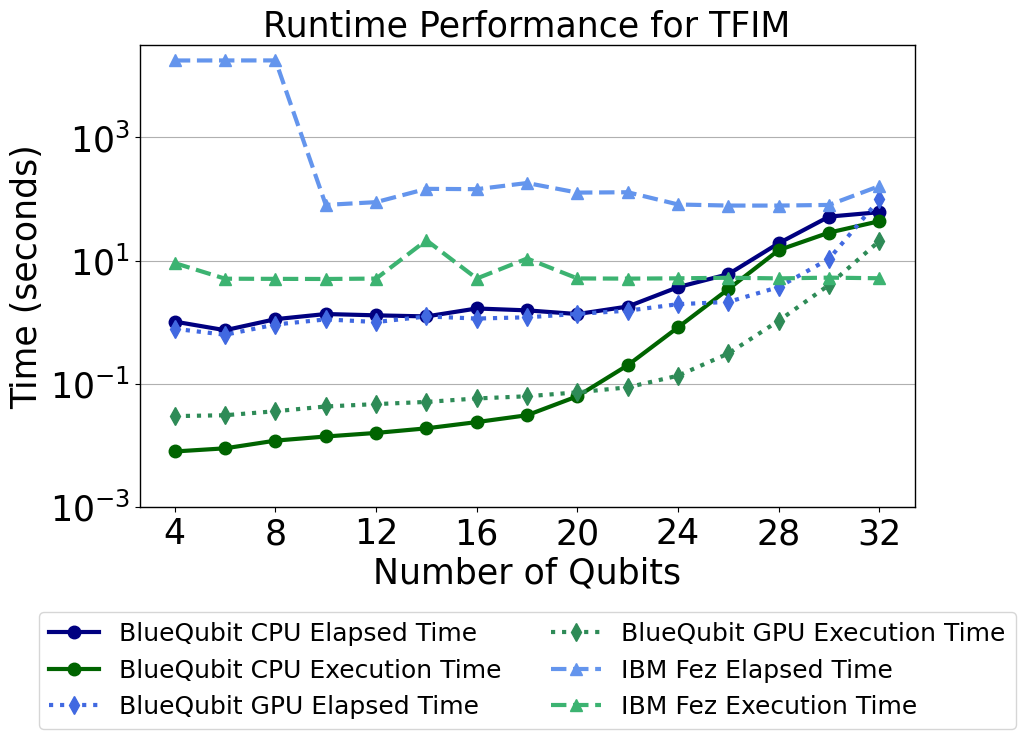

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import json
from time import gmtime, strftime

# Define markers and corresponding line styles for different simulators
mark_list = ['o', 'd', '^']
line_styles = {
    'o': '-',
    'd': ':',
    '^': '--'
}

# Define different shades of blue and green for plotting
colors_blue = ['Navy', 'RoyalBlue', 'CornflowerBlue']  # Deep blue, normal blue, lighter blue
colors_green = ['darkgreen', 'SeaGreen', 'MediumSeaGreen'] # Deep green, normal green, lighter green

def compare_test_results(data_list, test_list, title=None):
    # Custom legend names
    custom_legends = {
        'BQ-CPU-240820-TFIM-1-s10k': {
            'Elapsed Time': 'BlueQubit CPU Elapsed Time',
            'Exec Time': 'BlueQubit CPU Execution Time'
        },
        'BQ-GPU-240820-TFIM-1-s10k': {
            'Elapsed Time': 'BlueQubit GPU Elapsed Time',
            'Exec Time': 'BlueQubit GPU Execution Time'
        },
        'ibm_fez-240820-TFIM-1-s10k': {
            'Elapsed Time': 'IBM Fez Elapsed Time',
            'Exec Time': 'IBM Fez Execution Time'
        }
    }

    results = {}
    for data_file in data_list:
        with open(f'__data/DATA-{data_file}.json', 'r') as f:
            results[data_file] = json.load(f)

    fidelity = {}
    execution_time = {}
    elapsed_time = {}
    
    for data_file, res in results.items():
        fidelity[data_file] = {}
        execution_time[data_file] = {}
        elapsed_time[data_file] = {}

        for test in test_list:
            test_key = f"Benchmark Results - {test} - Qiskit"
            try:
                nqubits = results[data_file][test_key]['group_metrics']['groups']
                exec_t = results[data_file][test_key]['group_metrics']['avg_exec_times']
                execution_time[data_file][test_key] = {int(n): exec_t for n, exec_t in zip(nqubits, exec_t)}
                elapsed_t = results[data_file][test_key]['group_metrics']['avg_elapsed_times']
                elapsed_time[data_file][test_key] = {int(n): elapsed_t for n, elapsed_t in zip(nqubits, elapsed_t)}
            except KeyError:
                print(f"{test_key} wasn't run in data file {data_file}.") 

    fig, ax = plt.subplots(len(test_list), 1, figsize=(10, 6))
    if len(test_list) == 1:
        ax = [ax]

    for i, test in enumerate(test_list):
        test_key = f"Benchmark Results - {test} - Qiskit"
        for j, data_file in enumerate(data_list):
            xvalues = np.array(list(execution_time[data_file][test_key].keys()))
            exec_yvalues = np.array(list(execution_time[data_file][test_key].values()))
            elapsed_yvalues = np.array(list(elapsed_time[data_file][test_key].values()))

            marker = mark_list[j]
            linestyle = line_styles.get(marker, '-')

            ax[i].plot(xvalues, elapsed_yvalues, marker=marker, markersize=9, color=colors_blue[j], 
                       label=custom_legends[data_file]['Elapsed Time'], linestyle=linestyle, linewidth=3)
            ax[i].plot(xvalues, exec_yvalues, marker=marker, markersize=9, color=colors_green[j], 
                       label=custom_legends[data_file]['Exec Time'], linestyle=linestyle, linewidth=3)

        ax[i].set_ylabel('Time (seconds)', fontsize=25)
        ax[i].set_ylim(0.001, 31622)
        
        # Set the x-axis ticks to 4, 8, 12, ...
        x_ticks = np.arange(4, max(xvalues) + 1, 4)
        ax[i].set_xticks(x_ticks)
        ax[i].set_xticklabels([str(x) for x in x_ticks], fontsize=25)
        
        ax[i].tick_params(axis='y', labelsize=25)  # Set y-axis tick label size
        ax[i].legend(fontsize=18, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
        ax[i].set_yscale('log')
        ax[i].grid(axis='y')  # Show only horizontal grid lines
        ax[i].spines['top'].set_linewidth(1)
        ax[i].spines['bottom'].set_linewidth(1)
        ax[i].spines['left'].set_linewidth(1)
        ax[i].spines['right'].set_linewidth(1)
    
    timestr = strftime("%Y-%m-%d %H:%M:%S", gmtime())
    if title:
        ax[0].set_title(f"{title}", fontsize=25)
    else:
        ax[0].set_title('Benchmarking results - ' + ', '.join([name.split(' - ')[1] for name in test_list]), fontsize=25)
    
    ax[-1].set_xlabel('Number of Qubits', fontsize=25)
    fig.savefig('__images/' + 'time_comparison_tfim_new.pdf', format='pdf', bbox_inches='tight')
    plt.show()

# Example usage
compare_test_results(['BQ-CPU-240820-TFIM-1-s10k', 'BQ-GPU-240820-TFIM-1-s10k', 'ibm_fez-240820-TFIM-1-s10k'], 
                     ["Hamiltonian Simulation"], 
                     title="Runtime Performance for TFIM")


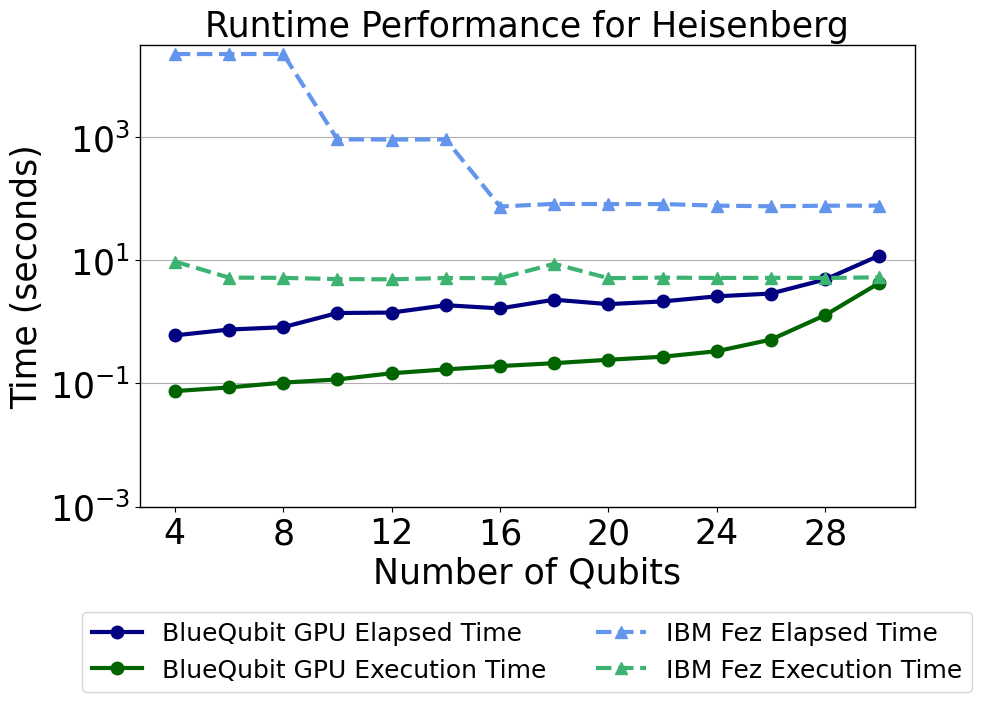

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import json
from time import gmtime, strftime

# Define markers and corresponding line styles for different simulators
mark_list = ['o', '^']
line_styles = {
    'o': '-',
    '^': '--'
}

# Define different shades of blue and green for plotting
colors_blue = ['Navy', 'CornflowerBlue']  # Deep blue, normal blue, lighter blue
colors_green = ['darkgreen', 'MediumSeaGreen'] # Deep green, normal green, lighter green

def compare_test_results(data_list, test_list, title=None):
    # Custom legend names
    custom_legends = {
        'BQ-GPU-240820-HEIS-1-s10k': {
            'Elapsed Time': 'BlueQubit GPU Elapsed Time',
            'Exec Time': 'BlueQubit GPU Execution Time'
        },
        'ibm_fez-240820-HEIS-1-s10k': {
            'Elapsed Time': 'IBM Fez Elapsed Time',
            'Exec Time': 'IBM Fez Execution Time'
        }
    }

    results = {}
    for data_file in data_list:
        with open(f'__data/DATA-{data_file}.json', 'r') as f:
            results[data_file] = json.load(f)

    fidelity = {}
    execution_time = {}
    elapsed_time = {}
    
    for data_file, res in results.items():
        fidelity[data_file] = {}
        execution_time[data_file] = {}
        elapsed_time[data_file] = {}

        for test in test_list:
            test_key = f"Benchmark Results - {test} - Qiskit"
            try:
                nqubits = results[data_file][test_key]['group_metrics']['groups']
                exec_t = results[data_file][test_key]['group_metrics']['avg_exec_times']
                execution_time[data_file][test_key] = {int(n): exec_t for n, exec_t in zip(nqubits, exec_t)}
                elapsed_t = results[data_file][test_key]['group_metrics']['avg_elapsed_times']
                elapsed_time[data_file][test_key] = {int(n): elapsed_t for n, elapsed_t in zip(nqubits, elapsed_t)}
            except KeyError:
                print(f"{test_key} wasn't run in data file {data_file}.") 

    fig, ax = plt.subplots(len(test_list), 1, figsize=(10, 6))
    if len(test_list) == 1:
        ax = [ax]

    for i, test in enumerate(test_list):
        test_key = f"Benchmark Results - {test} - Qiskit"
        for j, data_file in enumerate(data_list):
            xvalues = np.array(list(execution_time[data_file][test_key].keys()))
            exec_yvalues = np.array(list(execution_time[data_file][test_key].values()))
            elapsed_yvalues = np.array(list(elapsed_time[data_file][test_key].values()))

            marker = mark_list[j]
            linestyle = line_styles.get(marker, '-')

            ax[i].plot(xvalues, elapsed_yvalues, marker=marker, markersize=9, color=colors_blue[j], 
                       label=custom_legends[data_file]['Elapsed Time'], linestyle=linestyle, linewidth=3)
            ax[i].plot(xvalues, exec_yvalues, marker=marker, markersize=9, color=colors_green[j], 
                       label=custom_legends[data_file]['Exec Time'], linestyle=linestyle, linewidth=3)

        ax[i].set_ylabel('Time (seconds)', fontsize=25)
        
        # Set the x-axis ticks to 4, 8, 12, ...
        x_ticks = np.arange(4, max(xvalues) + 1, 4)
        ax[i].set_xticks(x_ticks)
        ax[i].set_xticklabels([str(x) for x in x_ticks], fontsize=25)
        ax[i].set_ylim(0.001, 31622)
        
        ax[i].tick_params(axis='y', labelsize=25)  # Set y-axis tick label size
        ax[i].legend(fontsize=18, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
        ax[i].set_yscale('log')
        ax[i].grid(axis='y')  # Show only horizontal grid lines
        ax[i].spines['top'].set_linewidth(1)
        ax[i].spines['bottom'].set_linewidth(1)
        ax[i].spines['left'].set_linewidth(1)
        ax[i].spines['right'].set_linewidth(1)
    
    timestr = strftime("%Y-%m-%d %H:%M:%S", gmtime())
    if title:
        ax[0].set_title(f"{title}", fontsize=25)
    else:
        ax[0].set_title('Benchmarking results - ' + ', '.join([name.split(' - ')[1] for name in test_list]), fontsize=25)
    
    ax[-1].set_xlabel('Number of Qubits', fontsize=25)
    fig.savefig('__images/' + 'time_comparison_heis_new.pdf', format='pdf', bbox_inches='tight')
    plt.show()

# Example usage
compare_test_results(['BQ-GPU-240820-HEIS-1-s10k', 'ibm_fez-240820-HEIS-1-s10k'], 
                     ["Hamiltonian Simulation"], 
                     title="Runtime Performance for Heisenberg")
